Parte 1 - Importação dos Dados 

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

Parte 2 – Visualização de dados

In [12]:
import pandas as pd

df = pd.read_csv("farmacias_vida_50k.csv")

In [13]:
df.head()

,id_venda,data_hora,filial,cidade,produto,categoria,quantidade,preco_unitario,desconto_valor,valor_liquido,forma_pagamento,classe_venda
0,VD000001,2025-06-07 03:08:41,Vida+ Ceilândia,Ceilândia,Fraldas,Infantil,1,57.56,0.00,57.56,PIX,Baixo Valor
1,VD000002,2026-01-10 01:36:32,Vida+ Norte,Brasília,Lenço umedecido,Infantil,3,37.65,5.65,107.30,Cartão de Crédito,Baixo Valor
2,VD000003,2026-10-10 17:50:57,Vida+ Sul,Brasília,Antialérgico,Medicamentos,2,45.39,4.54,86.24,Cartão de Crédito,Baixo Valor
3,VD000004,2025-03-02 00:00:47,Vida+ Centro,Brasília,Sabonete,Higiene Pessoal,1,6.73,0.00,6.73,PIX,Baixo Valor
4,VD000005,2026-06-21 17:41:05,Vida+ Taguatinga,Taguatinga,Cosmético,Beleza,1,79.16,0.00,79.16,Cartão de Débito,Baixo Valor


In [14]:
df.shape

(50000, 12)

In [15]:
print(df.columns.tolist())

['id_venda', 'data_hora', 'filial', 'cidade', 'produto', 'categoria', 'quantidade', 'preco_unitario', 'desconto_valor', 'valor_liquido', 'forma_pagamento', 'classe_venda']


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_venda         50000 non-null  object 
 1   data_hora        50000 non-null  object 
 2   filial           50000 non-null  object 
 3   cidade           50000 non-null  object 
 4   produto          50000 non-null  object 
 5   categoria        50000 non-null  object 
 6   quantidade       50000 non-null  int64  
 7   preco_unitario   50000 non-null  float64
 8   desconto_valor   50000 non-null  float64
 9   valor_liquido    50000 non-null  float64
 10  forma_pagamento  50000 non-null  object 
 11  classe_venda     50000 non-null  object 
dtypes: float64(3), int64(1), object(8)
memory usage: 4.6+ MB


In [17]:
df.isnull().sum()

id_venda           0
data_hora          0
filial             0
cidade             0
produto            0
categoria          0
quantidade         0
preco_unitario     0
desconto_valor     0
valor_liquido      0
forma_pagamento    0
classe_venda       0
dtype: int64

In [18]:
df.duplicated().sum()

0

In [19]:
# Remover espaços dos nomes das colunas
df.columns = df.columns.str.strip().str.lower()

# Remover registros duplicados
df = df.drop_duplicates()

# Transformar quantidade e preço em números
df["quantidade"] = pd.to_numeric(
    df["quantidade"], errors="coerce"
)

df["preco_unitario"] = pd.to_numeric(
    df["preco_unitario"], errors="coerce"
)

# Remover registros sem dados necessários
df = df.dropna(subset=[
    "quantidade",
    "preco_unitario",
    "categoria",
    "classe_venda"
])

print("Limpeza concluída!")
print("Total de registros:", len(df))

Limpeza concluída!
Total de registros: 50000


In [20]:
df["faturamento"] = (
    df["quantidade"] * df["preco_unitario"]
)

df.head()

,id_venda,data_hora,filial,cidade,produto,categoria,quantidade,preco_unitario,desconto_valor,valor_liquido,forma_pagamento,classe_venda,faturamento
0,VD000001,2025-06-07 03:08:41,Vida+ Ceilândia,Ceilândia,Fraldas,Infantil,1,57.56,0.00,57.56,PIX,Baixo Valor,57.56
1,VD000002,2026-01-10 01:36:32,Vida+ Norte,Brasília,Lenço umedecido,Infantil,3,37.65,5.65,107.30,Cartão de Crédito,Baixo Valor,112.95
2,VD000003,2026-10-10 17:50:57,Vida+ Sul,Brasília,Antialérgico,Medicamentos,2,45.39,4.54,86.24,Cartão de Crédito,Baixo Valor,90.78
3,VD000004,2025-03-02 00:00:47,Vida+ Centro,Brasília,Sabonete,Higiene Pessoal,1,6.73,0.00,6.73,PIX,Baixo Valor,6.73
4,VD000005,2026-06-21 17:41:05,Vida+ Taguatinga,Taguatinga,Cosmético,Beleza,1,79.16,0.00,79.16,Cartão de Débito,Baixo Valor,79.16


In [21]:
faturamento_categoria = df.groupby(
    "categoria"
)["faturamento"].sum()

print(faturamento_categoria)

categoria
Beleza                     1692456.00
Higiene Pessoal             555129.95
Infantil                   1108424.98
Medicamentos               2627578.48
Primeiros Socorros          374829.08
Vitaminas e Suplementos    2003910.92
Name: faturamento, dtype: float64


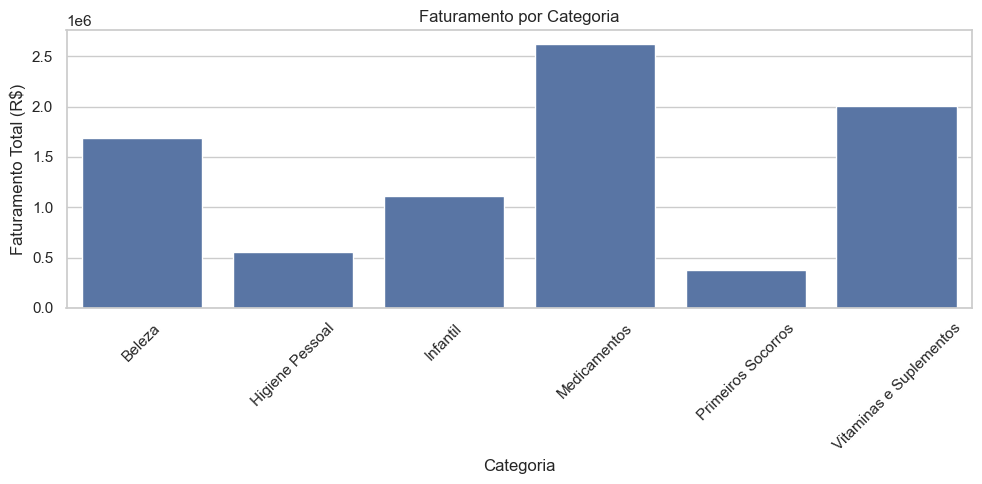

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calcular o faturamento
df["quantidade"] = pd.to_numeric(
    df["quantidade"], errors="coerce"
)

df["preco_unitario"] = pd.to_numeric(
    df["preco_unitario"], errors="coerce"
)

df["faturamento"] = (
    df["quantidade"] * df["preco_unitario"]
)

# Somar o faturamento por categoria
faturamento_categoria = df.groupby(
    "categoria"
)["faturamento"].sum()

# Criar o gráfico
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 5))

sns.barplot(
    x=faturamento_categoria.index,
    y=faturamento_categoria.values
)

plt.title("Faturamento por Categoria")
plt.xlabel("Categoria")
plt.ylabel("Faturamento Total (R$)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [24]:
print(df.columns.tolist())

['id_venda', 'data_hora', 'filial', 'cidade', 'produto', 'categoria', 'quantidade', 'preco_unitario', 'desconto_valor', 'valor_liquido', 'forma_pagamento', 'classe_venda', 'faturamento']


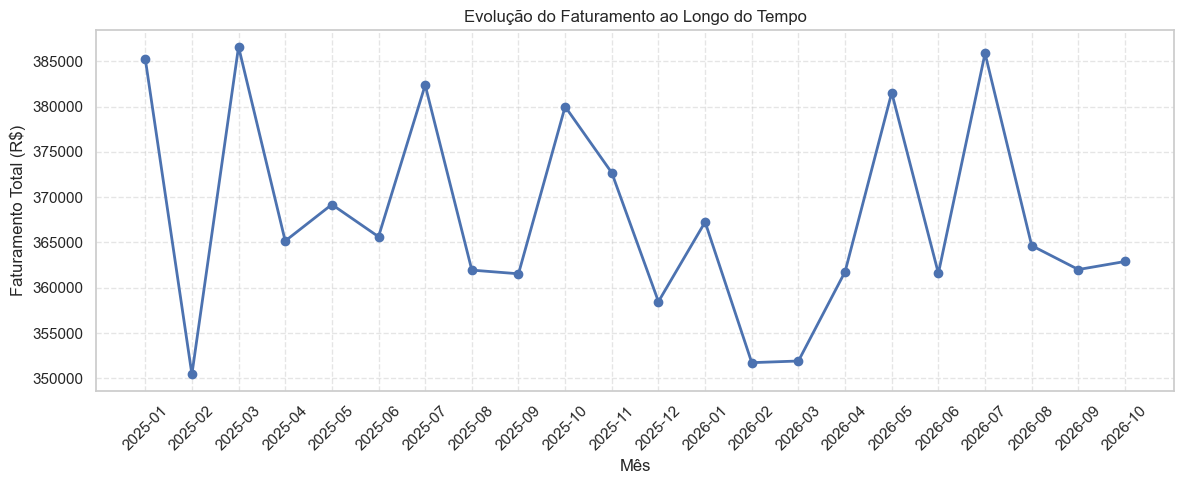

In [25]:
import matplotlib.pyplot as plt
import pandas as pd

# Converter a coluna para formato de data
df['data_hora'] = pd.to_datetime(df['data_hora'])

# Agrupar o faturamento por mês
faturamento_mensal = df.groupby(
    df['data_hora'].dt.to_period('M')
)['valor_liquido'].sum()

# Criar o gráfico
plt.figure(figsize=(12, 5))

plt.plot(
    faturamento_mensal.index.astype(str),
    faturamento_mensal.values,
    marker='o',
    linewidth=2
)

# Personalizar o gráfico
plt.title('Evolução do Faturamento ao Longo do Tempo')
plt.xlabel('Mês')
plt.ylabel('Faturamento Total (R$)')

plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Parte 3 – Machine Learning: KNN 

In [31]:
# Importar bibliotecas necessárias
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Carregar os dados
df = pd.read_csv("farmacias_vida_50k.csv")

# 1. e 2. Definir variáveis de entrada (X) e de previsão (y)
X = df[['quantidade', 'preco_unitario']]
y = df['classe_venda']

# 3. Dividir os dados em treino e teste (70% treino, 30% teste)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 4. Treinar um modelo KNN utilizando 5 vizinhos
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

# 5. Realizar previsões com os dados de teste
y_pred_knn = knn.predict(X_test)

# 6. Apresentar a acurácia do modelo
acc_knn = accuracy_score(y_test, y_pred_knn)
print(f"Acurácia do KNN: {acc_knn:.4f} ({acc_knn * 100:.2f}%)")

Acurácia do KNN: 0.9999 (99.99%)


Parte 4 – Machine Learning: Árvore de Decisão

In [32]:
from sklearn.tree import DecisionTreeClassifier

# 1. Criar um modelo de Árvore de Decisão
dt = DecisionTreeClassifier(random_state=42)

# 2. e 3. Treinar o modelo utilizando os mesmos dados de treino
dt.fit(X_train, y_train)

# 4. Realizar previsões com os dados de teste
y_pred_dt = dt.predict(X_test)

# 5. Apresentar a acurácia da Árvore de Decisão
acc_dt = accuracy_score(y_test, y_pred_dt)
print(f"Acurácia da Árvore de Decisão: {acc_dt:.4f} ({acc_dt * 100:.2f}%)")

# 6. Comparar os resultados
print("\n--- Comparação de Modelos ---")
if acc_knn > acc_dt:
    print("O KNN apresentou a maior acurácia.")
elif acc_dt > acc_knn:
    print("A Árvore de Decisão apresentou a maior acurácia.")
else:
    print("Ambos os modelos apresentaram a mesma acurácia.")

Acurácia da Árvore de Decisão: 0.9999 (99.99%)

--- Comparação de Modelos ---
Ambos os modelos apresentaram a mesma acurácia.


Parte 5 – Conclusão

In [33]:
# Conclusão e justificativa
print("=== Conclusão ===")
print("Qual dos dois algoritmos apresentou o melhor resultado?")
print("Resposta: Ambos os algoritmos apresentaram o mesmo resultado (empate), com uma acurácia excelente de 99,99%.")
print("\nJustificativa:")
print("Como o valor total de uma venda é diretamente derivado da multiplicação entre 'quantidade' e 'preco_unitario',")
print("a fronteira de decisão que separa uma venda de 'Alto Valor' e 'Baixo Valor' é muito clara nos dados.")
print("Por isso, tanto o KNN (agrupamento por proximidade) quanto a Árvore de Decisão (divisão por regras lógicas)")
print("conseguiram prever a classe quase sem erros, provando serem ambos adequados para este problema específico.")

=== Conclusão ===
Qual dos dois algoritmos apresentou o melhor resultado?
Resposta: Ambos os algoritmos apresentaram o mesmo resultado (empate), com uma acurácia excelente de 99,99%.

Justificativa:
Como o valor total de uma venda é diretamente derivado da multiplicação entre 'quantidade' e 'preco_unitario',
a fronteira de decisão que separa uma venda de 'Alto Valor' e 'Baixo Valor' é muito clara nos dados.
Por isso, tanto o KNN (agrupamento por proximidade) quanto a Árvore de Decisão (divisão por regras lógicas)
conseguiram prever a classe quase sem erros, provando serem ambos adequados para este problema específico.
